In [437]:
# Import the librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from scipy.stats import mannwhitneyu  
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#loading the dataset
df = pd.read_csv('AI_Usage_and_Impact_on_Students_and_Professionals.csv')


In [438]:
#Viewing the data
print(f'The dataset set as {df.shape[0]} rows and {df.shape[1]} columns')
df.head(10)

The dataset set as 300 rows and 19 columns


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes
5,U0225,19,NaN,United States,Student,Undergraduate,Business Analytics Student,774,Meta AI,Data Analysis,1.5,"Statistical analysis on datasets, data visuali...",0,5.0,3.0,6.0,2.9,7.4,No
6,U0246,32,Male,france,Professional,Bachelor's,Développeur Full Stack,4466,ChatGPT,Coding,1.2,"Automated code review with AI-powered linters,...",20,3.0,2.0,5.0,6.6,6.4,Yes
7,U0177,32,Male,Philippines,Professional,High School,Social Media Content Creator,486,ChatGPT,Content Creation,2,Creating Instagram/TikTok captions with AI wri...,0,6.5,2.0,5.0,3.2 hrs,6.4,Yes
8,U0207,16,Male,Philippines,Student,Undergraduate,Digital Media Production Student,132,Claude,Content Creation,1.6 hrs,"Creating YouTube video scripts, Designing soci...",30,4.7,4.0,6.0,3.8,3.8,Yes
9,U0167,40,male,india,Professional,High School,NaN,1595,ChatGPT,Writing,1.7,"Email copywriting, Social media post creation,...",10,NaN,2.0,5.0,7.5,9.4,Maybe


## 1. Data cleaning

In [439]:
# standardizing the column names
df.columns = df.columns.str.strip().str.lower()
df.columns

Index(['user_id', 'age', 'gender', 'country', 'user_type', 'education_level',
       'profession', 'monthly_income', 'ai_tool', 'ai_purpose',
       'ai_usage_hours_per_day', 'tasks_performed', 'monthly_ai_cost',
       'productivity_score', 'accuracy_rating', 'satisfaction_score',
       'time_saved_hours_per_week', 'work_or_study_hours_per_day',
       'would_recommend'],
      dtype='object')

In [440]:
#stanrdizing the data types of the columns
# Extract string values from the numeric column and convert them to int or float format for analysis

#for "age" column
df['age'] = pd.to_numeric(
     df['age'].str.extract(r'(\d+)')[0], 
     errors='coerce'
     ).astype('Int64')

#for "montgly income" column
df['monthly_income'] = pd.to_numeric(
    df['monthly_income'].str.extract(r'(\d+)')[0],
    errors='coerce'
)
# for "ai usage hours per day " column
df['ai_usage_hours_per_day'] = pd.to_numeric(
    df['ai_usage_hours_per_day'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

#for "monnthly ai cost" column
df['monthly_ai_cost'] = pd.to_numeric(
    df['monthly_ai_cost'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

#for "time saved  hours per week" column
df['time_saved_hours_per_week'] = pd.to_numeric(
    df['time_saved_hours_per_week'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

#for "work or study hours per day" column
df['work_or_study_hours_per_day'] = pd.to_numeric(
    df['work_or_study_hours_per_day'].str.extract(r'(\d+)')[0],
    errors='coerce')

In [441]:
df.dtypes

user_id                         object
age                              Int64
gender                          object
country                         object
user_type                       object
education_level                 object
profession                      object
monthly_income                 float64
ai_tool                         object
ai_purpose                      object
ai_usage_hours_per_day         float64
tasks_performed                 object
monthly_ai_cost                float64
productivity_score             float64
accuracy_rating                float64
satisfaction_score             float64
time_saved_hours_per_week      float64
work_or_study_hours_per_day    float64
would_recommend                 object
dtype: object

In [442]:
#fixing the inconsistent categorical values 

#for the "gender" column
df['gender'] = df['gender'].replace({
    'M': 'Male', 
    'male':'Male',
    'MALE': 'Male',

    'F': 'Female',
    'female':'Female',
    'FEMALE': 'Female',

    'other':'Other', 'Non-binary':'Other'})


#for the "country" column 
df['country'] = df['country'].replace({
    'brazil':'Brazil', 'india':'India', 'canada':'Canada',
    'United States of America':'United States', 'france':'France',
    'U.K.':'United Kingdom','philippines':'Philippines', 'australia':'Australia',
})

#for the "education level" column
df['education_level'] = df['education_level'].replace({
    'Bachelor\'s':'Bachelor', 
    'Bachelors':'Bachelor', 
    'bachelor\'s degree':'Bachelor',
    'BA/BSc':'Bachelor',

    'undergrad':'Undergraduate', 
    'Master\'s':'Master', 
    'Masters':'Master', 
    'master\'s degree':'Master', 
    'MA/MSc':'Master',

    'Ph.D.':'PhD', 
    'high school':'High School',
    'HS':' High School', 
    ' High School':'High School'
})

#for ai tool column
df['ai_tool'] = df['ai_tool'].replace({
    'chatgpt': 'ChatGPT',
    'Chat GPT': 'ChatGPT',
    'Chatgpt': 'ChatGPT',

    'gemini': 'Gemini',
    'Google Gemini': 'Gemini',

    'Microsoft Copilot': 'Copilot',
    ' Copilot':'Copilot',
    'copilot':'Copilot',

    'claude': 'Claude'
})


In [443]:
df.head(10) 

,user_id,age,gender,country,user_type,education_level,profession,monthly_income,ai_tool,ai_purpose,ai_usage_hours_per_day,tasks_performed,monthly_ai_cost,productivity_score,accuracy_rating,satisfaction_score,time_saved_hours_per_week,work_or_study_hours_per_day,would_recommend
0,U0269,30,Male,United Kingdom,Professional,Master,Business Analyst,5421.0,ChatGPT,Office Work,2.0,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.0,7.0,Yes
1,U0217,30,Male,United States,Professional,Bachelor,Customer Support Specialist,8903.0,ChatGPT,Customer Support,5.0,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.0,8.0,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402.0,ChatGPT,Coding,1.0,NaN,20.0,3.2,2.0,4.0,5.0,6.0,No
3,U0264,35,Female,Brazil,Professional,Bachelor,Desenvolvedora de Software / Software Developer,1367.0,Meta AI,Coding,1.0,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.0,9.0,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity AI,NaN,4.0,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.0,6.0,Yes
5,U0225,19,NaN,United States,Student,Undergraduate,Business Analytics Student,774.0,Meta AI,Data Analysis,1.0,"Statistical analysis on datasets, data visuali...",0.0,5.0,3.0,6.0,2.0,7.0,No
6,U0246,32,Male,France,Professional,Bachelor,Développeur Full Stack,4466.0,ChatGPT,Coding,1.0,"Automated code review with AI-powered linters,...",20.0,3.0,2.0,5.0,6.0,6.0,Yes
7,U0177,32,Male,Philippines,Professional,High School,Social Media Content Creator,486.0,ChatGPT,Content Creation,2.0,Creating Instagram/TikTok captions with AI wri...,0.0,6.5,2.0,5.0,3.0,6.0,Yes
8,U0207,16,Male,Philippines,Student,Undergraduate,Digital Media Production Student,132.0,Claude,Content Creation,1.0,"Creating YouTube video scripts, Designing soci...",30.0,4.7,4.0,6.0,3.0,3.0,Yes
9,U0167,40,Male,India,Professional,High School,NaN,1595.0,ChatGPT,Writing,1.0,"Email copywriting, Social media post creation,...",10.0,NaN,2.0,5.0,7.0,9.0,Maybe


In [444]:
#checking for missing values
missing = df.isna().sum()
missing_pct = missing/len(df)* 100
missing_df = pd.DataFrame({
    'missing': missing,
    'missing_pct': missing_pct
})
missing_df

,missing,missing_pct
user_id,0,0.000000
age,23,7.666667
gender,10,3.333333
country,10,3.333333
user_type,0,0.000000
education_level,13,4.333333
profession,15,5.000000
monthly_income,10,3.333333
ai_tool,11,3.666667
ai_purpose,13,4.333333


In [445]:
#Imputing with the mode for the categorical values 
# global Mode
for col in ['gender', 'country', 'profession']:
    df[col] = df[col].fillna(df[col].mode()[0])

# education_level based on profession
df['education_level'] = (
    df.groupby('profession')['education_level']
      .transform(lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else np.nan))
)

# ai_tool based on profession
df['ai_tool'] = (
    df.groupby('profession')['ai_tool']
      .transform(lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else np.nan))
)

# ai_purpose based on profession
df['ai_purpose'] = (
    df.groupby('profession')['ai_purpose']
      .transform(lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else np.nan))
)


df['would_recommend'] = (
    df.groupby('ai_tool')['would_recommend']
      .transform(lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else np.nan))
)

# in case there is still null values
cat_cols = [
   'education_level','ai_tool','ai_purpose',
   'would_recommend'
]

for col in cat_cols:
   df[col] = df[col].fillna(df[col].mode()[0])

# for the "tasks_performed" column 
df['tasks_performed']= df["tasks_performed"].fillna('Unknown')

C:\Users\AramSamb\AppData\Local\Temp\ipykernel_19316\3877343208.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else np.nan))
C:\Users\AramSamb\AppData\Local\Temp\ipykernel_19316\3877343208.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else np.nan))
C:\Users\AramSamb\AppData\Local\Temp\ipykernel_19316\3877343208.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated an

The tasks_performed feature consisted of detailed free-text descriptions of AI-assisted activities. Due to its high cardinality, substantial overlap with the ai_purpose feature, missing values were labeled as "Unknown" and the feature will be excluded  from the final machine learning dataset.

In [446]:
# fillingt the numerical columns with the median as its more robust than the mean
# age based on education_level
df['age'] = (
    df.groupby('education_level')['age']
      .transform(lambda x: x.fillna(x.median()))
)

# monthly_income based profession
df['monthly_income'] = (
    df.groupby('profession')['monthly_income']
      .transform(lambda x: x.fillna(x.median()))
)

# ai_usage_hours_per_day based on ai_purpose
df['ai_usage_hours_per_day'] = (
    df.groupby('ai_purpose')['ai_usage_hours_per_day']
      .transform(lambda x: x.fillna(x.median()))
)

# monthly_ai_cost based on ai_tool
df['monthly_ai_cost'] = (
    df.groupby('ai_tool')['monthly_ai_cost']
      .transform(lambda x: x.fillna(x.median()))
)

# productivity_score based on ai_purpose
df['productivity_score'] = (
    df.groupby('ai_purpose')['productivity_score']
      .transform(lambda x: x.fillna(x.median()))
)

# accuracy_rating based on  ai_tool
df['accuracy_rating'] = (
    df.groupby('ai_tool')['accuracy_rating']
      .transform(lambda x: x.fillna(x.median()))
)

# satisfaction_score based ai_tool
df['satisfaction_score'] = (
    df.groupby('ai_tool')['satisfaction_score']
      .transform(lambda x: x.fillna(x.median()))
)

# time_saved_hours_per_week based on  ai_purpose
df['time_saved_hours_per_week'] = (
    df.groupby('ai_purpose')['time_saved_hours_per_week']
      .transform(lambda x: x.fillna(x.median()))
)

# work_or_study_hours_per_day based on  user_type
df['work_or_study_hours_per_day'] = (
    df.groupby('user_type')['work_or_study_hours_per_day']
      .transform(lambda x: x.fillna(x.median()))
)

# filet de sécurité : médiane globale
num_cols = [
    'age',
    'monthly_income',
    'ai_usage_hours_per_day',
    'monthly_ai_cost',
    'productivity_score',
    'accuracy_rating',
    'satisfaction_score',
    'time_saved_hours_per_week',
    'work_or_study_hours_per_day'
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

c:\Users\AramSamb\Documents\sp\venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\AramSamb\Documents\sp\venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\AramSamb\Documents\sp\venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\AramSamb\Documents\sp\venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


In [447]:
df.isna().sum()

user_id                        0
age                            0
gender                         0
country                        0
user_type                      0
education_level                0
profession                     0
monthly_income                 0
ai_tool                        0
ai_purpose                     0
ai_usage_hours_per_day         0
tasks_performed                0
monthly_ai_cost                0
productivity_score             0
accuracy_rating                0
satisfaction_score             0
time_saved_hours_per_week      0
work_or_study_hours_per_day    0
would_recommend                0
dtype: int64

In [448]:
# checking for duplicates
duplicates= df.duplicated().sum()
df= df.drop_duplicates()
print(f' {duplicates} duplicated rows were drop , only {df.shape[0]} remain.')

 12 duplicated rows were drop , only 288 remain.


## 2. Feature engineering

In [449]:
#viewing the unicity of user id 
df['user_id'].nunique()

288

In [450]:
# weekly usage of ai in hours
df['weekly_ai_usage_hours']= df['ai_usage_hours_per_day']*7 

# productivity per hour
df['productivity_per_hour']= df['productivity_score']/df['ai_usage_hours_per_day']

# time saved per ai hour
df['time_saved_per_ai_hour'] = (df['time_saved_hours_per_week'] /df['weekly_ai_usage_hours'])

# ai cost efficiency
df['ai_cost_efficiency']= df['time_saved_hours_per_week']/ (df['monthly_ai_cost']+ 1)

# high ai user , segmmentation by users ( 1: high, 0: normal)
median_usage= df['ai_usage_hours_per_day'].median()
df['high_ai_user']=np.where( df['ai_usage_hours_per_day'] > median_usage,1, 0)

# heavy ai spender, user investiving consequently on ai 
median_cost = df['monthly_ai_cost'].median()
df['heavy_ai_spender'] =  np.where(df['monthly_ai_cost'] > median_cost,1,0)

In [451]:
#categorising the productivity levels with ai 
df['productivity_category'] = pd.cut(
    df['productivity_score'],
    bins=[0,4,7,10],
    labels=['Low','Medium','High']
)

#categorising the satisfaction with ai 
df['satisfaction_category'] = pd.cut(
    df['satisfaction_score'],
    bins=[0,4,7,10],
    labels=['Low','Medium','High']
)

# to determine if revenue influence ai adoption
df['income_category'] = pd.qcut(
    df['monthly_income'],
    q=3,
    labels=['Low Income','Middle Income','High Income']
)

# categorising by age group
df['age_group'] =pd.qcut(
    df['age'],
    q=3,
    labels=['Young Adult', 'Middle-Age', 'Old']
)

In [452]:
df.head()

,user_id,age,gender,country,user_type,education_level,profession,monthly_income,ai_tool,ai_purpose,...,weekly_ai_usage_hours,productivity_per_hour,time_saved_per_ai_hour,ai_cost_efficiency,high_ai_user,heavy_ai_spender,productivity_category,satisfaction_category,income_category,age_group
0,U0269,30,Male,United Kingdom,Professional,Master,Business Analyst,5421.0,ChatGPT,Office Work,...,14.0,2.650,0.214286,3.000000,0,0,Medium,Medium,High Income,Middle-Age
1,U0217,30,Male,United States,Professional,Bachelor,Customer Support Specialist,8903.0,ChatGPT,Customer Support,...,35.0,1.980,0.314286,11.000000,1,0,High,High,High Income,Middle-Age
2,U0152,17,Male,Canada,Student,High School,Computer Science Student,402.0,ChatGPT,Coding,...,7.0,3.200,0.714286,0.238095,0,1,Low,Low,Middle Income,Young Adult
3,U0264,35,Female,Brazil,Professional,Bachelor,Desenvolvedora de Software / Software Developer,1367.0,Meta AI,Coding,...,7.0,5.600,0.857143,0.285714,0,1,Medium,Medium,High Income,Old
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity AI,Studying,...,28.0,1.175,0.321429,9.000000,1,0,Medium,Medium,Middle Income,Young Adult


In [453]:
df.describe()

c:\Users\AramSamb\Documents\sp\venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\AramSamb\Documents\sp\venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,age,monthly_income,ai_usage_hours_per_day,monthly_ai_cost,productivity_score,accuracy_rating,satisfaction_score,time_saved_hours_per_week,work_or_study_hours_per_day,weekly_ai_usage_hours,productivity_per_hour,time_saved_per_ai_hour,ai_cost_efficiency,high_ai_user,heavy_ai_spender
count,288.0,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,273.000000,288.000000,288.000000,288.000000
mean,29.920139,2278.541667,2.437500,9.565972,5.221181,3.407986,6.126736,5.326389,6.777778,17.062500,inf,inf,3.036616,0.357639,0.454861
std,12.037856,14794.141998,2.482605,13.719533,1.778090,0.839594,1.507963,4.058509,2.013697,17.378235,NaN,NaN,3.995577,0.480139,0.498825
min,16.0,0.000000,0.000000,0.000000,1.600000,2.000000,3.000000,0.000000,2.000000,0.000000,0.178261,0.000000,0.000000,0.000000,0.000000
25%,22.0,112.250000,1.000000,0.000000,4.000000,3.000000,5.000000,2.000000,6.000000,7.000000,1.700000,0.238095,0.191850,0.000000,0.000000
50%,27.0,518.000000,2.000000,0.000000,5.000000,3.000000,6.000000,5.000000,7.000000,14.000000,2.700000,0.333333,1.000000,0.000000,0.000000
75%,35.0,1580.000000,3.250000,20.000000,6.200000,4.000000,7.000000,7.000000,8.000000,22.750000,4.900000,0.571429,5.000000,1.000000,1.000000
max,97.0,250000.000000,23.000000,100.000000,10.000000,5.000000,10.000000,19.000000,20.000000,161.000000,inf,inf,17.000000,1.000000,1.000000


In [454]:
df[['productivity_per_hour',
    'time_saved_per_ai_hour']].isna().sum()

productivity_per_hour      0
time_saved_per_ai_hour    15
dtype: int64

In [455]:
df['productivity_per_hour'] = (
    df['productivity_per_hour']
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

df['time_saved_per_ai_hour'] = (
    df['time_saved_per_ai_hour']
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

In [456]:
df.describe()

,age,monthly_income,ai_usage_hours_per_day,monthly_ai_cost,productivity_score,accuracy_rating,satisfaction_score,time_saved_hours_per_week,work_or_study_hours_per_day,weekly_ai_usage_hours,productivity_per_hour,time_saved_per_ai_hour,ai_cost_efficiency,high_ai_user,heavy_ai_spender
count,288.0,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000
mean,29.920139,2278.541667,2.437500,9.565972,5.221181,3.407986,6.126736,5.326389,6.777778,17.062500,2.352596,0.310431,3.036616,0.357639,0.454861
std,12.037856,14794.141998,2.482605,13.719533,1.778090,0.839594,1.507963,4.058509,2.013697,17.378235,1.689683,0.265558,3.995577,0.480139,0.498825
min,16.0,0.000000,0.000000,0.000000,1.600000,2.000000,3.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,22.0,112.250000,1.000000,0.000000,4.000000,3.000000,5.000000,2.000000,6.000000,7.000000,1.315000,0.142857,0.191850,0.000000,0.000000
50%,27.0,518.000000,2.000000,0.000000,5.000000,3.000000,6.000000,5.000000,7.000000,14.000000,2.066667,0.285714,1.000000,0.000000,0.000000
75%,35.0,1580.000000,3.250000,20.000000,6.200000,4.000000,7.000000,7.000000,8.000000,22.750000,3.400000,0.428571,5.000000,1.000000,1.000000
max,97.0,250000.000000,23.000000,100.000000,10.000000,5.000000,10.000000,19.000000,20.000000,161.000000,9.400000,2.142857,17.000000,1.000000,1.000000


### Key Observations

- The average respondent is 30 years old.
- Users spend approximately 2.4 hours per day using AI tools, equivalent to 17 hours per week.
- AI helps users save an average of 5.3 hours per week.
- Satisfaction with AI (6.1/10) exceeds reported productivity gains (5.2/10).
- Income levels vary considerably, indicating a diverse user population.
- Several extreme values were detected and will be investigated during the outlier analysis stage.

## 3. Exploratory data analysis

###  Dataset overview

Text(0.5, 1.0, 'Distribution of User Types')

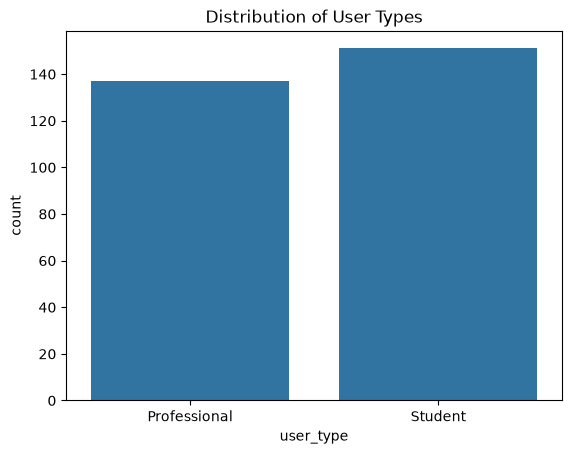

In [457]:
# Are there more students or professionals in the dataset ?
sns.countplot(data=df, x='user_type')
plt.title('Distribution of User Types')

In [458]:
# Count and percentage of each user type
user_counts = df['user_type'].value_counts()
user_percentages = df['user_type'].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    'Count': user_counts,
    'Percentage (%)': user_percentages.round(2)
})

summary

,Count,Percentage (%)
user_type,,
Student,151,52.43
Professional,137,47.57


The dataset is relatively balanced between students (52.4%) and professionals (47.6%), making it suitable for comparative analyses of AI adoption and impact across both groups.

###  Student vs professional analysis

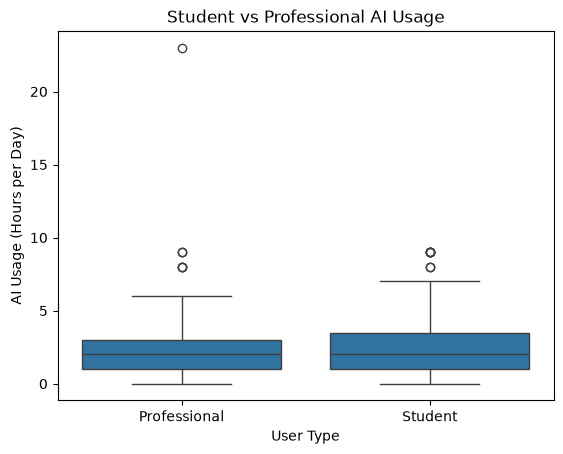

In [459]:
# Who tends to use AI more?
sns.boxplot(data=df, x='user_type', y='ai_usage_hours_per_day')

plt.title('Student vs Professional AI Usage')
plt.xlabel('User Type')
plt.ylabel('AI Usage (Hours per Day)')
plt.show()

Students and professionals use AI at very similar levels, with a typical usage of around 2 hours per day for both groups. Students show slightly more variation in usage, while a few professionals report extremely high usage, reaching almost 23 hours per day.

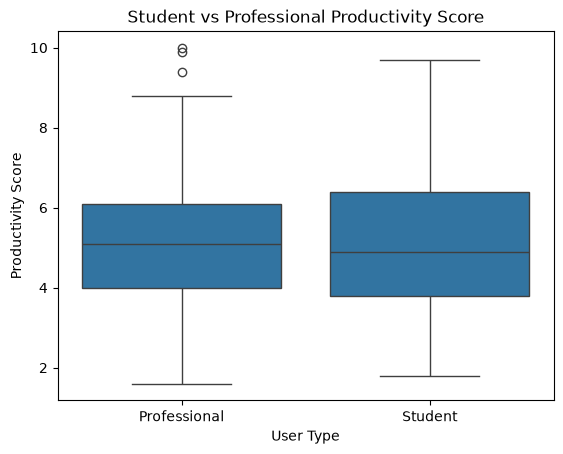

In [460]:
# who benefits more from AI usage
sns.boxplot(data=df, x='user_type', y='productivity_score')

plt.title('Student vs Professional Productivity Score')
plt.xlabel('User Type')
plt.ylabel('Productivity Score')
plt.show()

Both students and professionals report comparable productivity gains from AI, with a typical productivity score of around 5 out of 10. This suggests that AI delivers similar perceived benefits in both academic and professional settings.

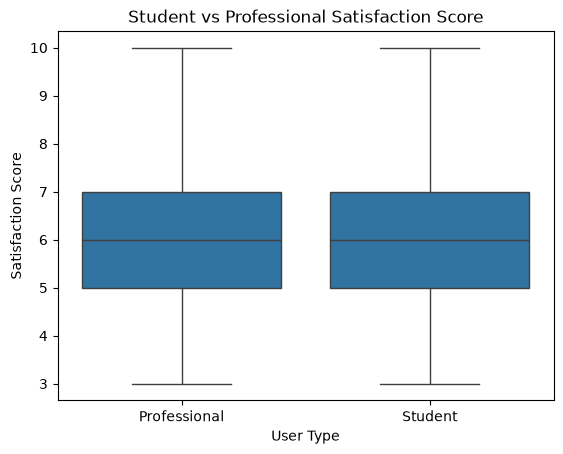

In [461]:
# who is more satisfied from AI usage
sns.boxplot(data=df, x='user_type', y='satisfaction_score')

plt.title('Student vs Professional Satisfaction Score')
plt.xlabel('User Type')
plt.ylabel('Satisfaction Score')
plt.show()

Satisfaction levels are nearly identical across both groups. The typical satisfaction score is 6 out of 10 for both students and professionals, suggesting that AI tools are perceived similarly regardless of user type.

###  AI tool analysis

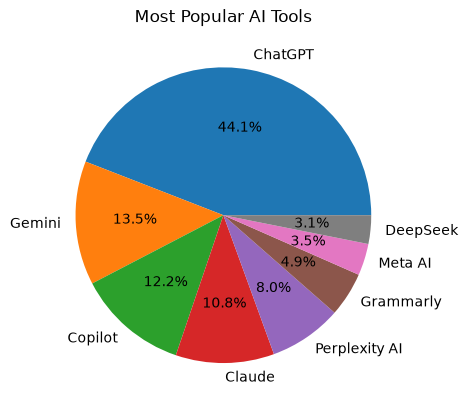

In [462]:
# Which tool is more popular?
df['ai_tool'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Most Popular AI Tools')
plt.ylabel('') 
plt.show()

- ChatGPT dominates AI adoption, with approximately 44.1% users, representing more than three times the number of users of the next most popular tool, Gemini (13.5% users).
- Gemini, Copilot, and Claude form a second tier of adoption with roughly 10%-14% users each, while tools such as Meta AI, Grammarly, and DeepSeek remain niche solutions in this dataset.

C:\Users\AramSamb\AppData\Local\Temp\ipykernel_19316\1968260961.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['ai_usage_hours_per_day']


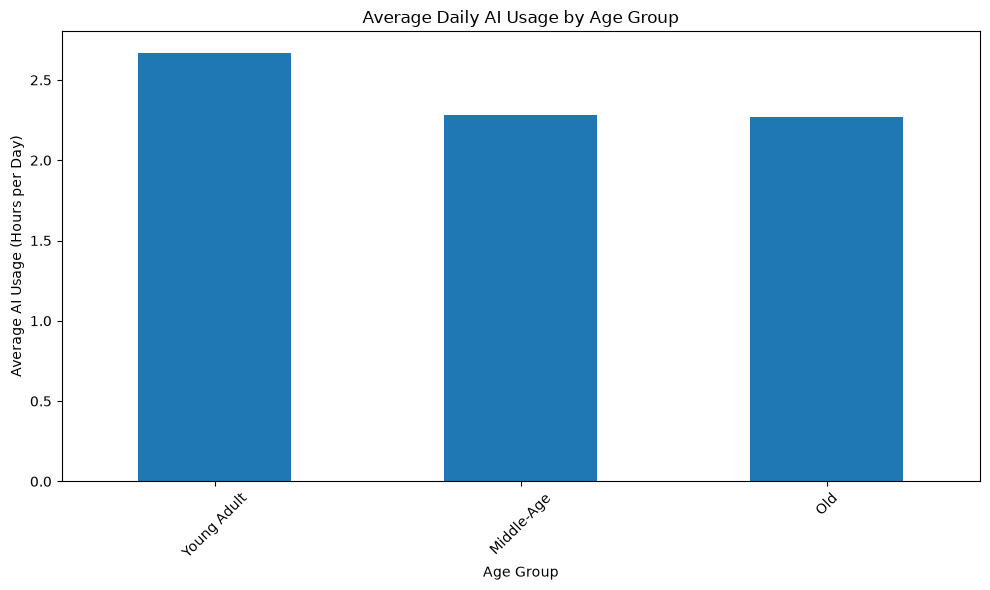

In [463]:
# Which age group use AI more?
country_usage = (
    df.groupby('age_group')['ai_usage_hours_per_day']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

country_usage.plot(kind='bar', figsize=(10, 6))

plt.title('Average Daily AI Usage by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average AI Usage (Hours per Day)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

While young adults use AI slightly more frequently, daily AI usage remains fairly consistent across all age groups, indicating broad adoption regardless of age.

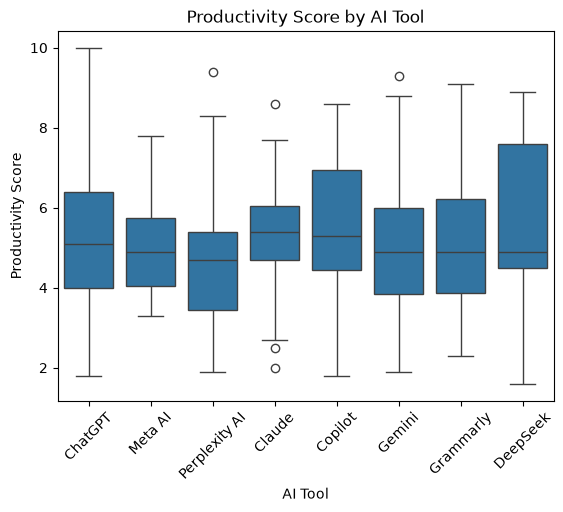

In [464]:
# Which AI tool is associated with higher productivity?
sns.boxplot(data=df, x='ai_tool', y='productivity_score')
plt.title('Productivity Score by AI Tool')
plt.xlabel('AI Tool')
plt.ylabel('Productivity Score')
plt.xticks(rotation=45)
plt.show()

- Productivity scores are relatively similar across AI tools, with most median scores falling between 4.5 and 5.5 out of 10.
- Claude and Copilot show slightly higher typical productivity scores than most other tools, suggesting users may perceive greater productivity benefits when using these platforms.
- Although ChatGPT is the most widely used tool, its productivity scores are broadly comparable to those of competing AI tools, indicating that popularity does not necessarily translate into higher perceived productivity

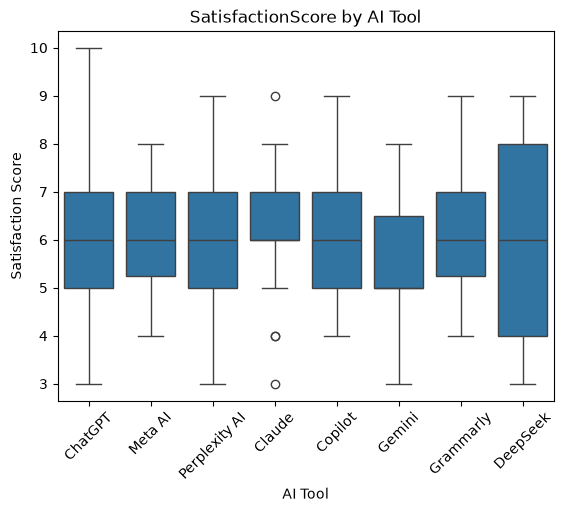

In [465]:
# Which AI tool has a higher satisfactions score?
sns.boxplot(data=df, x='ai_tool', y='satisfaction_score')
plt.title('SatisfactionScore by AI Tool')
plt.xlabel('AI Tool')
plt.ylabel('Satisfaction Score')
plt.xticks(rotation=45)
plt.show()

- User satisfaction is remarkably consistent across AI tools, with a median satisfaction score of approximately 6 out of 10 for nearly every platform.
- DeepSeek shows greater variability in satisfaction ratings, indicating more diverse user experiences compared with other tools.

### AI purpose analysis

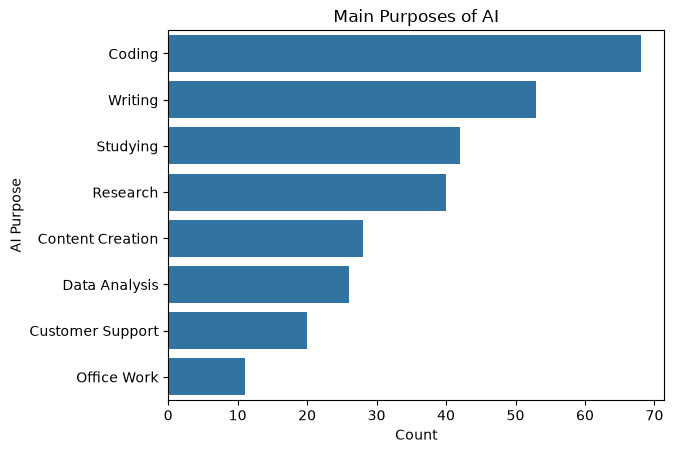

In [466]:
# What are the main purposes of AI?
sns.countplot(
    data=df,
    y='ai_purpose',
    order=df['ai_purpose'].value_counts().index
)

plt.title('Main Purposes of AI')
plt.xlabel('Count')
plt.ylabel('AI Purpose')
plt.show()

- Coding is the most common use case for AI, with nearly 70 users, making it the leading application in the dataset.
- Writing (≈54 users) and Studying (≈42 users) are also major use cases, highlighting the growing role of AI in both academic and content-creation activities.
- Office Work is the least common use case, with only about 11 users, suggesting that respondents rely on AI more for specialized tasks than routine administrative work.

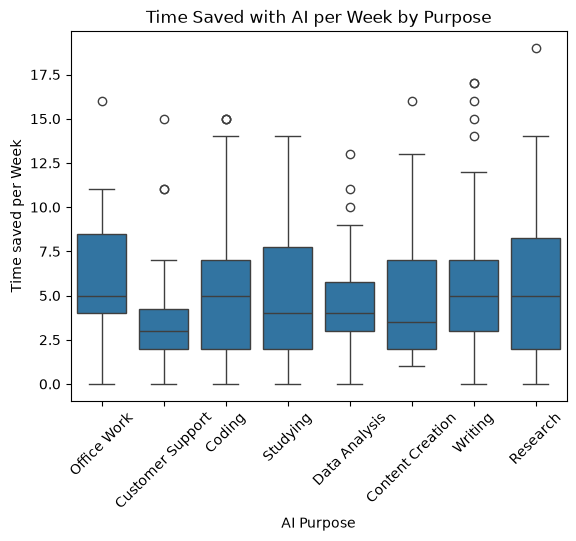

In [467]:
# Time saved vs purpose
sns.boxplot(data=df, x='ai_purpose', y='time_saved_hours_per_week')
plt.title('Time Saved with AI per Week by Purpose')
plt.xlabel('AI Purpose')
plt.ylabel('Time saved per Week')
plt.xticks(rotation=45)
plt.show()

- Users leveraging AI for office work,Research, Writing, and Coding report the highest median time savings, typically around 5 hours per week.
- Customer Support users report the lowest time savings, with a median closer to 3 hours per week, indicating more modest efficiency gains in this area.
- Research-related tasks and writtin show the highest maximum reported savings, reaching nearly 19 hours per week, suggesting that AI can significantly accelerate information gathering and analysis.

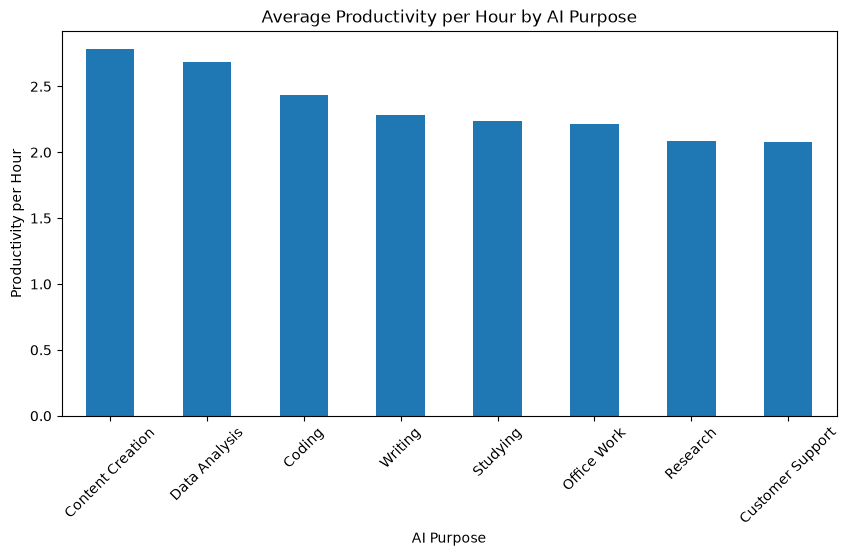

In [468]:
#Which AI purpose generates the highest productivity per hour of usage?
purpose_efficiency = (
    df.groupby('ai_purpose')['productivity_per_hour']
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))

purpose_efficiency.plot(kind='bar')

plt.title('Average Productivity per Hour by AI Purpose')
plt.xlabel('AI Purpose')
plt.ylabel('Productivity per Hour')

plt.xticks(rotation=45)

plt.show()

- Data Analysis, Coding, and Content Creation deliver the highest productivity per hour, each averaging around 3.0 productivity points per hour of AI use.
- Research and Office Work show the lowest productivity per hour, at approximately 2.4-2.5, suggesting these tasks may require more human effort despite AI assistance

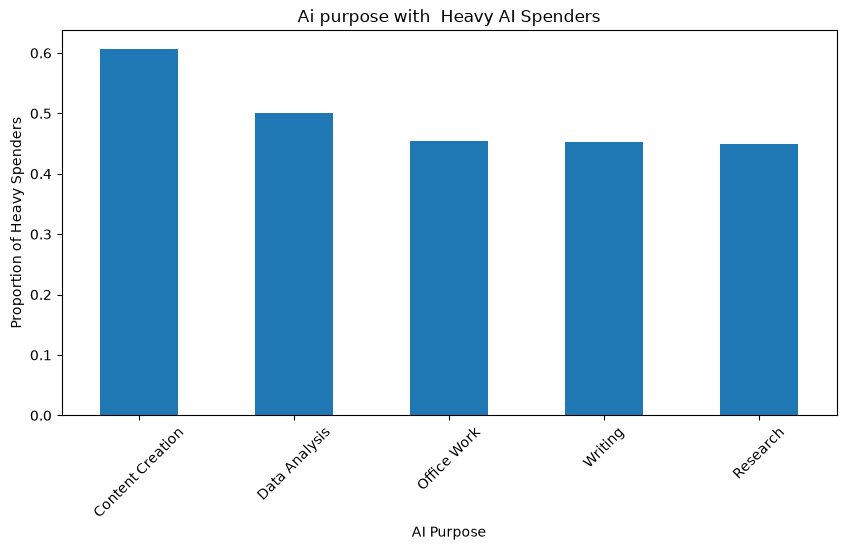

In [469]:
# Which purpose are more likely to get more invested in ?
heavy_spender_by_purpose = (
    df.groupby('ai_purpose')['heavy_ai_spender']
      .mean()
      .sort_values(ascending=False)
      .head(5)
)

plt.figure(figsize=(10,5))

heavy_spender_by_purpose.plot(kind='bar')

plt.title(' Ai purpose with  Heavy AI Spenders ')
plt.ylabel('Proportion of Heavy Spenders')
plt.xlabel('AI Purpose')

plt.xticks(rotation=45)

plt.show()

- Content Creation has the highest proportion of heavy AI spenders, with approximately 61% of users spending above the median on AI tools.
- Around 50% of Data Analysis users are heavy spenders, while Writing, Research, and Office Work are all close to 45%.

### Country analysis

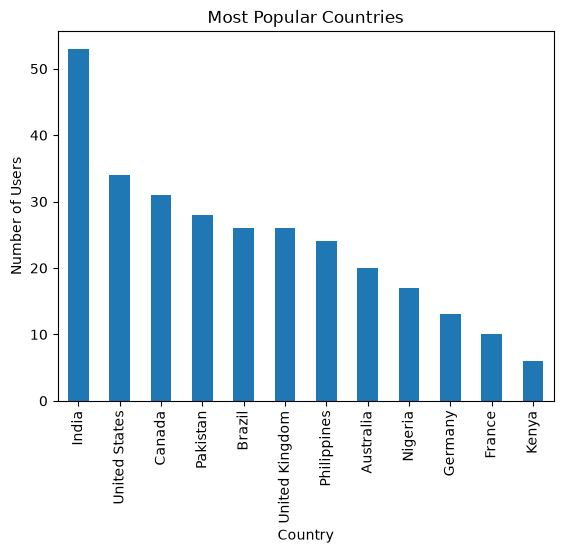

In [470]:
# which country is more represented
df['country'].value_counts().plot(kind='bar')
plt.title('Most Popular Countries')
plt.xlabel('Country')
plt.ylabel('Number of Users')
plt.show()

India is the most represented country in the dataset with 53 users, followed by the United States (34) and Canada (31).


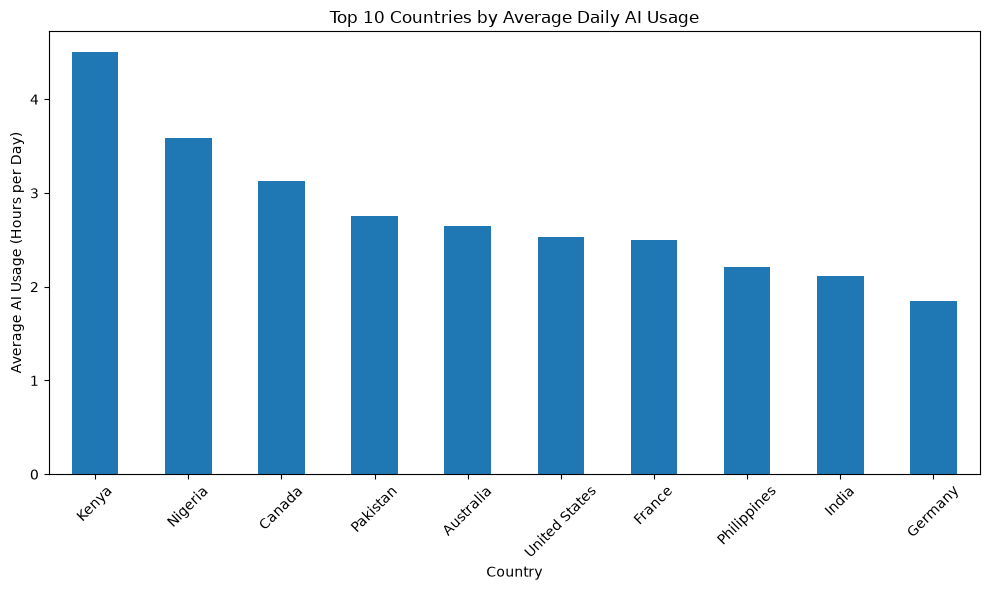

In [471]:
# Which countries use AI most intensively?
country_usage = (
    df.groupby('country')['ai_usage_hours_per_day']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

country_usage.plot(kind='bar', figsize=(10, 6))

plt.title('Top 10 Countries by Average Daily AI Usage')
plt.xlabel('Country')
plt.ylabel('Average AI Usage (Hours per Day)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- Kenya reports the highest average AI usage, with users spending approximately 4.5 hours per day using AI tools.
- Nigeria (3.6 hours/day) and Canada (3.1 hours/day) also rank among the highest AI users.
- Among the top 10 countries, Germany reports the lowest average usage, at approximately 1.9 hours per day.

### Income analysis

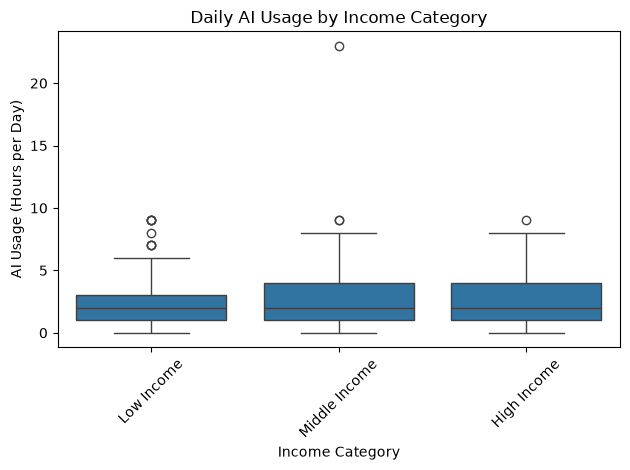

In [472]:
# Is AI usage by driven by income category
sns.boxplot(
    data=df,
    x='income_category',
    y='ai_usage_hours_per_day'
)

plt.title('Daily AI Usage by Income Category')
plt.xlabel('Income Category')
plt.ylabel('AI Usage (Hours per Day)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Income does not appear to be a strong driver of daily AI usage, as low-, middle-, and high-income users all report comparable levels of AI adoption.

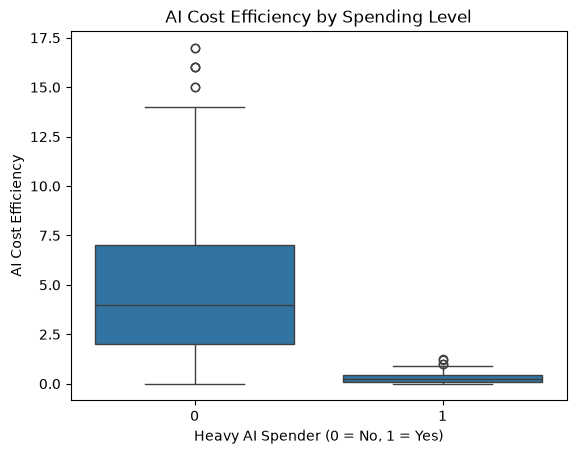

In [473]:
#Does spending more money actually translate into better efficiency?
sns.boxplot(
    data=df,
    x='heavy_ai_spender',
    y='ai_cost_efficiency'
)

plt.title('AI Cost Efficiency by Spending Level')
plt.xlabel('Heavy AI Spender (0 = No, 1 = Yes)')
plt.ylabel('AI Cost Efficiency')

plt.show()

Spending more on AI does not necessarily translate into better efficiency. Many lower-spending users appear to obtain more time savings for each dollar spent, suggesting diminishing returns from higher AI expenditures.

### Other business questions

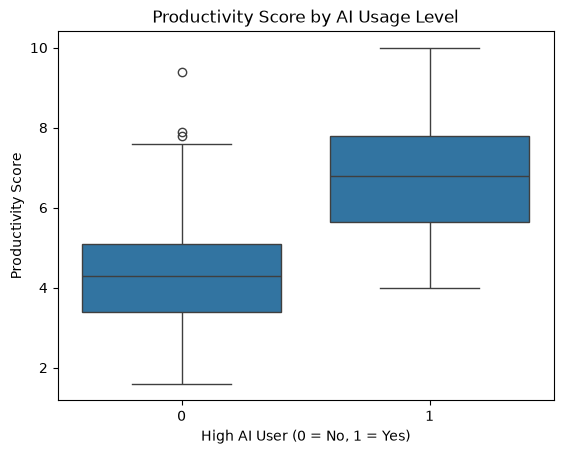

In [474]:
#Do heavy AI users achieve higher productivity scores?
sns.boxplot(
    data=df,
    x='high_ai_user',
    y='productivity_score'
)

plt.title('Productivity Score by AI Usage Level')
plt.xlabel('High AI User (0 = No, 1 = Yes)')
plt.ylabel('Productivity Score')

plt.show()

Users who rely on AI more frequently tend to report greater productivity gains,, with a median score of roughly 6.8/10, compared to 4.3/10 for regular users. This suggesting a positive relationship between AI usage intensity and perceived effectiveness.

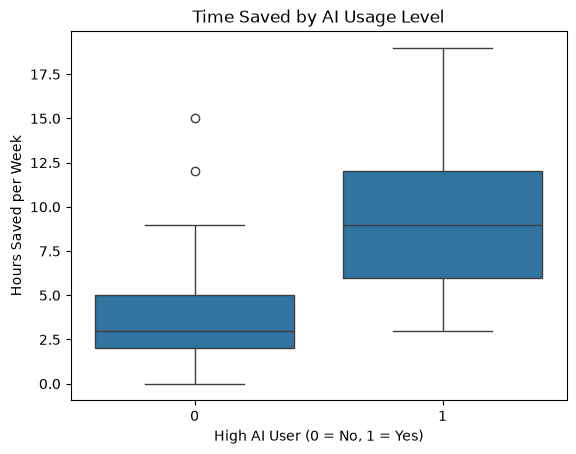

In [475]:
#Do heavy AI users save more time than regular users?
sns.boxplot(
    data=df,
    x='high_ai_user',
    y='time_saved_hours_per_week'
)

plt.title('Time Saved by AI Usage Level')
plt.xlabel('High AI User (0 = No, 1 = Yes)')
plt.ylabel('Hours Saved per Week')

plt.show()

Frequent AI usage is strongly associated with higher time savings ( 9 hours per week)compared to regular users( 3 hours per week), indicating that regular users may be extracting more value from AI tools.

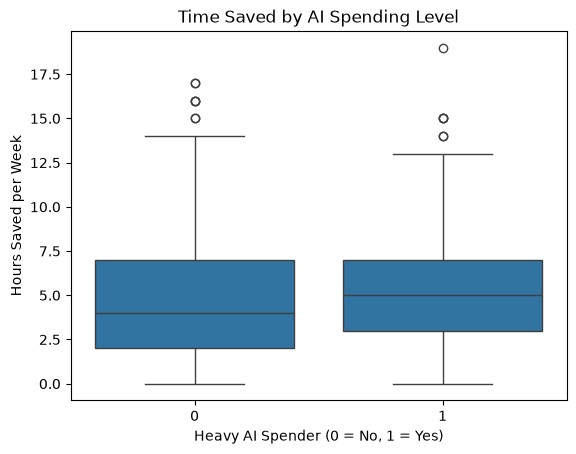

In [476]:
#Do heavy AI spenders save significantly more time?

sns.boxplot(
    data=df,
    x='heavy_ai_spender',
    y='time_saved_hours_per_week'
)

plt.title('Time Saved by AI Spending Level')
plt.xlabel('Heavy AI Spender (0 = No, 1 = Yes)')
plt.ylabel('Hours Saved per Week')

plt.show()

While heavy AI spenders save slightly more time, they achieve much lower cost efficiency, suggesting diminishing returns from higher AI expenditures.

## 4. Statistical testing 

#### Test 1 : Are high AI users really more productive?
- H0: There is no difference in productivity
-  H1: There is a difference in productivity

In [477]:
# checking normality with a  p-value (significance level) of 0.05
# if p-value < 0.05 the distribution is non normal
#if p-value > 0.05 , the distribution is normal

heavy = df[df['high_ai_user']==1]['productivity_score']
normal = df[df['high_ai_user']==0]['productivity_score']

print(shapiro(heavy))
print(shapiro(normal))

ShapiroResult(statistic=np.float64(0.979821212171889), pvalue=np.float64(0.11720489770845399))
ShapiroResult(statistic=np.float64(0.979821091996097), pvalue=np.float64(0.008883169449930088))


The Shapiro-Wilk test was conducted to assess the normality of productivity scores. While the distribution for high AI users did not significantly differ from normality (W = 0.97, p = .117), the distribution for regular AI users significantly deviated from normality (W = 0.97, p < .008). 

In [478]:
# using Mann-Whitney U test to compare productivity scores


heavy = df[df['high_ai_user'] == 1]['productivity_score']
normal = df[df['high_ai_user'] == 0]['productivity_score']

u_stat, p_value= mannwhitneyu(
    heavy,
    normal,
    alternative='two-sided'
)

print(f'U statistic: {u_stat:.3f}')
print(f'p-value: {p_value:.5f}')


U statistic: 17145.500
p-value: 0.00000


- A Mann-Whitney U test was conducted to compare productivity scores between heavy AI users and regular AI users as normality was violated i one group.
-  H1 is correct as there is a statistically significant difference in productivity scores between heavy AI users and regular users, U = 17145.5, p < .001. Heavy AI users reported significantly higher productivity scores. 

#### Test 2: Are Heavy AI Spenders associated with a specific AI Purpose?
- Heavy Ai spending is independent of AI purpose
- Heavy Ai spending is associated with AI purpose

In [479]:
contingency_table = pd.crosstab(
    df['ai_purpose'],
    df['heavy_ai_spender']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f'Chi-Square Statistic: {chi2:.3f}')
print(f'P-value: {p_value:.5f}')

Chi-Square Statistic: 3.726
P-value: 0.81076


In [480]:
(
    pd.crosstab(
        df['ai_purpose'],
        df['heavy_ai_spender'],
        normalize='index'
    ) * 100
).round(1)

heavy_ai_spender,0,1
ai_purpose,,
Coding,57.4,42.6
Content Creation,39.3,60.7
Customer Support,60.0,40.0
Data Analysis,50.0,50.0
Office Work,54.5,45.5
Research,55.0,45.0
Studying,59.5,40.5
Writing,54.7,45.3


- The Chi-Square test was selected because it assesses whether an association exists between two categorical variables: AI Purpose and Heavy AI Spending.
- The test found no statistically significant association between AI purpose and heavy AI spending, χ²(7) = 3.73, p = .811. This suggests that the likelihood of being a heavy AI spender does not significantly differ across AI usage purposes.
- The table also support it as we observe that although Content Creation users appear slightly more likely to be heavy AI spenders, spending behavior is generally similar across AI purposes. This suggests that users' willingness to invest in AI tools is not strongly driven by how they use AI, but may instead depend on other factors such as income, perceived value, or individual preferences.


## 5. Machine learning

Question: What drives satisfaction with AI tools?

In [481]:
# defining the target
y= df['satisfaction_score']

# dropping non-essential column also columns that could leak information
drop_cols= ['user_id','satisfaction_score','satisfaction_category','tasks_performed',
            'would_recommend']

X= df.drop(columns=drop_cols)

In [482]:
#encoding the categorical variables
X = pd.get_dummies(
    X,
    drop_first = True
)

In [483]:
# train, test, split the date
X_train,X_test,y_train,y_test= train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 42
)


In [484]:
#linear regression
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

#random forest regressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [485]:
# Evaluating the models

def evaluate_model(name, y_true, y_pred):

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    print(f'\n{name}')
    print('MAE:', round(mean_absolute_error(y_true, y_pred),3))
    print('RMSE:', round(rmse,3))
    print('R²:', round(r2_score(y_true, y_pred),3))


evaluate_model(
    'Linear Regression',
    y_test,
    lr_pred
)

evaluate_model(
    'Random Forest',
    y_test,
    rf_pred
)


Linear Regression
MAE: 0.891
RMSE: 1.12
R²: 0.475

Random Forest
MAE: 0.916
RMSE: 1.07
R²: 0.52


The Random Forest model outperformed Linear Regression across all evaluation metrics. It explained approximately 52% of the variance in user satisfaction, compared to 47% for Linear Regression, indicating that non-linear relationships exist between user characteristics, AI usage patterns, and satisfaction levels.

In [486]:
#feature importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

importance.head(15)

,Feature,Importance
4,productivity_score,0.419690
5,accuracy_rating,0.208909
1,monthly_income,0.037665
0,age,0.027746
11,ai_cost_efficiency,0.023985
10,time_saved_per_ai_hour,0.021880
9,productivity_per_hour,0.021555
7,work_or_study_hours_per_day,0.017970
6,time_saved_hours_per_week,0.014501
8,weekly_ai_usage_hours,0.014247


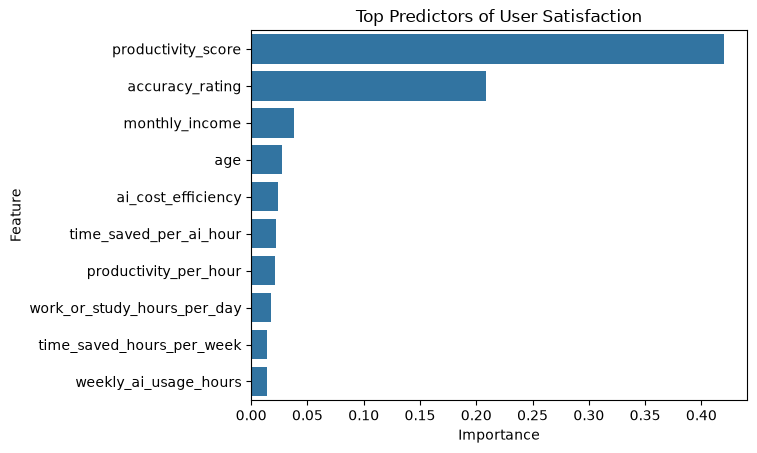

In [487]:
# Visualising the satisfaction score predictors

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top Predictors of User Satisfaction')

plt.show()


#####  Key drivers of ursers satisfaction:

1. Productivity is the strongest predictor of satisfaction

Productivity score is by far the most influential factor, accounting for over 40% of the model's predictive importance. Users who perceive greater productivity gains from AI tend to report much higher satisfaction levels.

2. Accuracy is the second most important factor

Accuracy rating is the second strongest predictor, suggesting that users value not only efficiency but also the quality and reliability of AI-generated outputs.

3. Financial and demographic factors have limited influence

Monthly income and age contribute relatively little to satisfaction compared to productivity and accuracy. This indicates that satisfaction is driven more by the benefits users receive from AI than by their personal characteristics.

4. Efficiency matters more than usage volume

Features such as AI cost efficiency, time saved per AI hour, and productivity per hour rank among the top predictors, showing that users tend to be more satisfied when they obtain greater value from each hour or dollar invested in AI.

5. Time savings contribute to satisfaction

Both time saved per week and time saved per AI hour appear among the most important predictors, suggesting that users appreciate AI most when it helps them complete tasks faster.

6. Usage intensity alone is not enough

Weekly AI usage hours has only a modest impact on satisfaction. Simply spending more time using AI does not guarantee higher satisfaction; the value generated from that usage appears to matter much more.

Final Business Insight:

User satisfaction with AI is primarily driven by results rather than usage habits. Users are most satisfied when AI improves their productivity, delivers accurate outputs, and helps them save time efficiently. In contrast, factors such as age, income, and overall usage volume play a much smaller role in shaping satisfaction levels.